# 1. Figures (sleep, work)

**Data:** sleep_hours_per_night, weekly_work_hours
**Output:** `reports/figures...`, This notebook plots graphs to be used for the report and showcases the distribution with diffrent plots

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from src.config import PROCESSED, FIGURES
df = pd.read_csv(PROCESSED / "clean_dataset.csv")


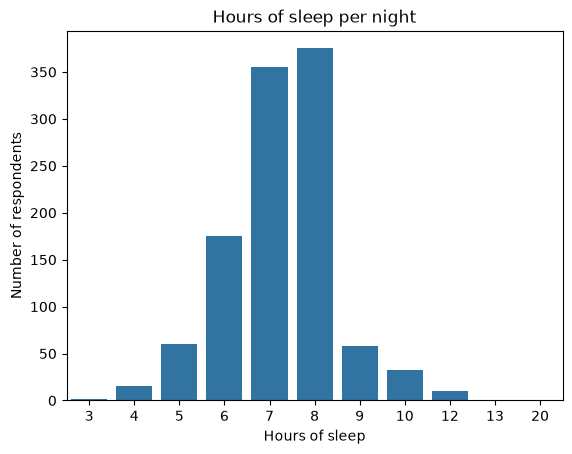

In [ ]:
fig, ax = plt.subplots()
sns.countplot(data=df, x="sleep_hours_per_night", ax=ax)
ax.set(title="Hours of sleep per night", xlabel="Hours of sleep", ylabel="Number of respondents")
for ext in ["png", "pdf"]:
    fig.savefig(FIGURES / f"sleep_hours_per_night_countplt.{ext}", bbox_inches="tight", dpi=300)

Most people sleep around 7+ hours concetrated moslty around 7 and 8. this would be conisdered in the recommended range with some outliers. there are some outliers but our data is mostlya as expected

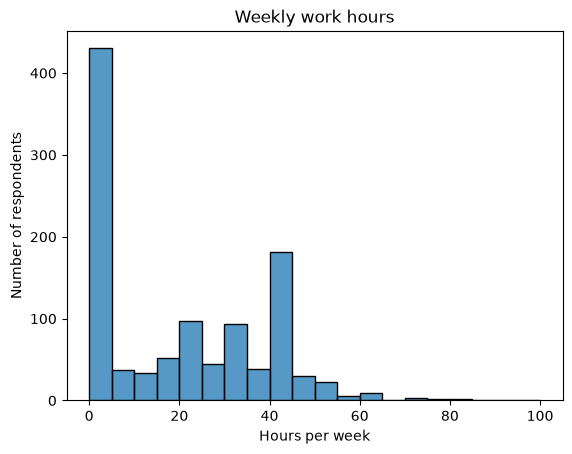

In [ ]:
fig, ax = plt.subplots()
sns.histplot(data=df, x="weekly_work_hours", binwidth=5, binrange=(0, 100), ax=ax)
ax.set(title="Weekly work hours", xlabel="Hours per week", ylabel="Number of respondents")
for ext in ["png", "pdf"]:
    fig.savefig(FIGURES / f"weekly_work_hours_histogram.{ext}", bbox_inches="tight", dpi=300)

this graph has binwidth 5 and we see peaks around 40h and 20h. it makes sense seeing them around standard part-time/full-time hours. there is also a lot of people who don't, which looks like to be a little less than half the respondants assuming there isn't a huge group of people working less than 4 and more than 0 hours

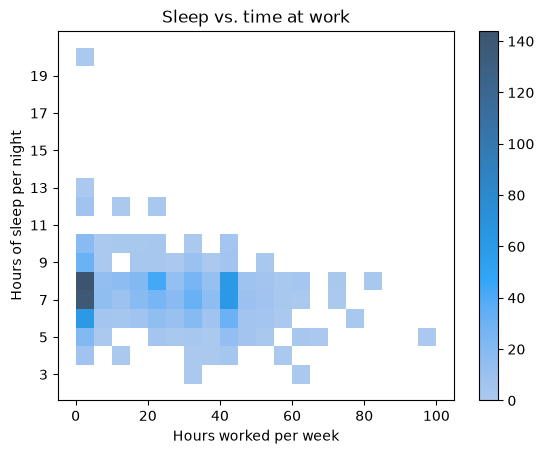

In [ ]:
fig, ax = plt.subplots()
sns.histplot(data=df, x="weekly_work_hours", y="sleep_hours_per_night",
             binwidth=(5, 1), binrange=((0, 100), (2.5, 20.5)),
             cbar=True, ax=ax)
ax.set_yticks(range(3, 21, 2))
ax.set(title="Sleep vs. time at work", xlabel="Hours worked per week",
       ylabel="Hours of sleep per night")
for ext in ["png", "pdf"]:
    fig.savefig(FIGURES / f"work_sleep_heatmap.{ext}", bbox_inches="tight", dpi=300)

The sleep spread of people who don't work is more varied, while it looks like sleep declines with amount of work. The data is pretty scarce, but given that they are students in addition to working naturally limits it some sense

In [ ]:
bins = [-1, 0, 9, 19, 29, 39, np.inf]
labels = ["0", "1–9", "10–19", "20–29", "30–39", "40+"]

df['working_hours_category'] = pd.cut(df['weekly_work_hours'], bins=bins, labels=labels)

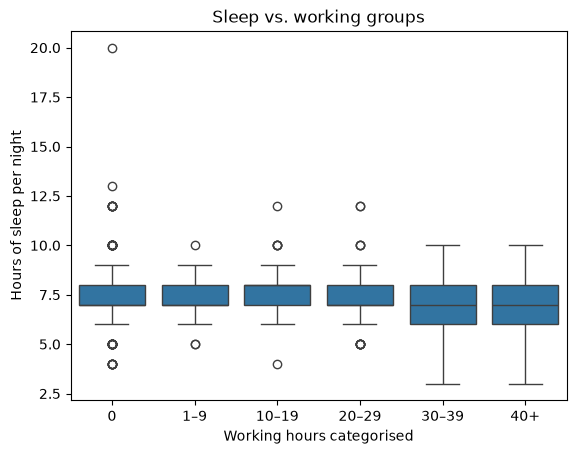

In [ ]:
fig, ax = plt.subplots()

sns.boxplot(x="working_hours_category", y="sleep_hours_per_night", data=df, ax=ax)
ax.set(title="Sleep vs. working groups", xlabel="Working hours categorised", ylabel="Hours of sleep per night")
for ext in ["png", "pdf"]:
    fig.savefig(FIGURES / f"work_sleep_boxplot.{ext}", bbox_inches="tight", dpi=300)

The groups containing 0-29 hours worked per week have a middle 50% of around 7-8 hours sleep per night, while the groups working more than 30 hours has a median dropping below 7 hours, with lower whiskers to about 3 hours. The difference between the groups is small and the boxes overlap, but we can see a correlation between higher working hours and less sleep.

working_hours_category
0        0.200957
1–9      0.224490
10–19    0.139535
20–29    0.232394
30–39    0.257576
40+      0.302326
Name: short_sleep, dtype: float64

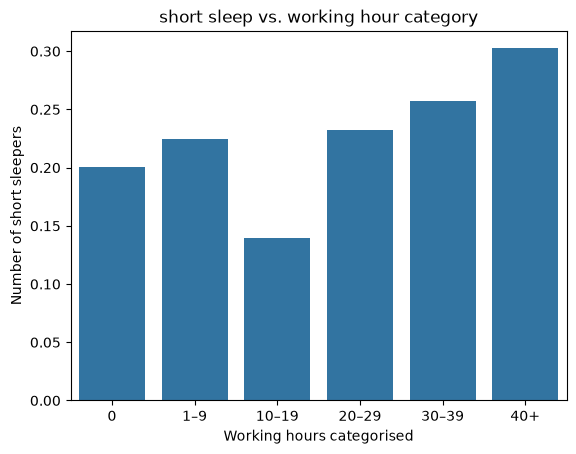

In [ ]:
fig, ax = plt.subplots()
sns.barplot(x="working_hours_category", y="short_sleep", data=df, errorbar=None, ax=ax)
ax.set(title="short sleep vs. working hour category", xlabel="Working hours categorised", ylabel="Number of short sleepers")
for ext in ["png", "pdf"]:
    fig.savefig(FIGURES / f"sleep_hours_per_night_countplt.{ext}", bbox_inches="tight", dpi=300)

The amount of short sleepers per group is relatively consistent, with the 10-19 hours of work group, while gradually becoming higher as working hours go up.

In [ ]:
r = df["weekly_work_hours"].corr(df["sleep_hours_per_night"]) 
rho = df["weekly_work_hours"].corr(df["sleep_hours_per_night"], method="spearman")
print(f"Pearson r = {r:.2f}, Spearman rho = {rho:.2f}")

Pearson r = -0.15, Spearman rho = -0.13


The correlation betweek weekly working hours and sleep hours is r = -0.15 in Pearson, and ρ = -0.13 in Spearnman, being a weak negative correlation. So we can see, which matches the plots, that people who work more sleep slightly less, with a visible, yet small difference. We can't conclude that working more directly causes less sleep, and other factors and varaibles could have an affect. 